In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
from ffxiv_stats.rate import Rate
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
rate = Rate(3000, 2000, 100)
p = rate.p
d2 = 10000
d2_2 = 12700

l_c = rate.crit_dmg_multiplier() / 1000

hit_damage = [d2, int(d2 * l_c), int(d2 * 1.25), int(d2 * l_c * 1.25)]
hit_damage2 = [d2_2, int(d2_2 * l_c), int(d2_2 * 1.25), int(d2_2 * l_c * 1.25)]
hit_damage

[10000, 15850, 12500, 19812]

In [16]:
from ffxiv_stats.support import ActionDistribution

action_dict = {
    "n": 100,
    "p_n": p[0],
    "p_c": p[1],
    "p_d": p[2],
    "p_cd": p[3],
    "d2": d2,
    "l_c": rate.l_c,
    "buffs": 1.15,
    "is_dot": False,
}

a = ActionDistribution(action_dict, 1, 10, compute_moments=False)

In [17]:
n_hits = 100
size = 1000000

random_hits = np.random.choice(hit_damage, p=rate.p, size=size*n_hits)
random_hits = (np.random.uniform(0.95, 1.050001, size=size*n_hits) * random_hits).astype(int) * 1.15

random_hits = random_hits.reshape((size, n_hits)).sum(axis=1)

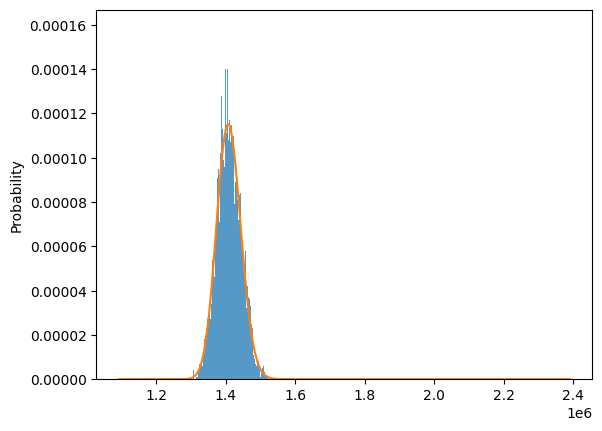

In [19]:
sns.histplot(random_hits, binwidth=10, stat="density")
plt.plot(a.action_support, a.action_pmf, c="C1")

In [8]:
fulgy = np.random.choice([0, 1], p=[0.65, 0.35], size=size)

d2_2 = 12700

fulgy[fulgy == 0] = np.random.choice(hit_damage, p=p, size=fulgy[fulgy == 0].shape)
fulgy[fulgy == 1] = np.random.choice(hit_damage2, p=p, size=fulgy[fulgy == 1].shape)

fulgy = (np.random.uniform(0.95, 1.050001, size=size) * fulgy).astype(int)


In [45]:
action_dict = {
    "n": 4,
    "p_n": p[0],
    "p_c": p[1],
    "p_d": p[2],
    "p_cd": p[3],
    "d2": [d2, d2_2],
    "l_c": rate.l_c,
    "buffs": 1.4,
    "is_dot": False,
    "w": [0.65, 0.35]
}

a = ActionDistribution(action_dict, 1, 10, compute_moments=False)

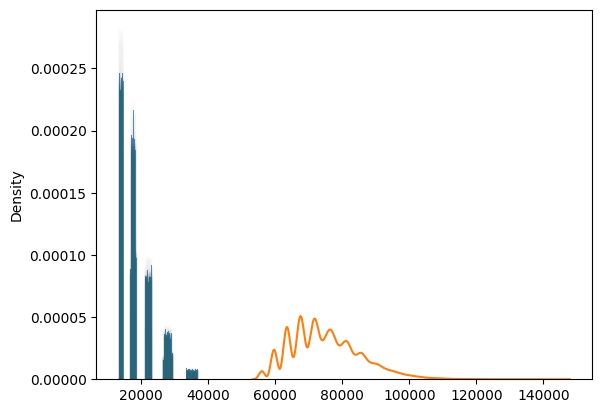

In [46]:
sns.histplot(fulgy * 1.4, binwidth=10, stat="density")
plt.plot(a.action_support, a.action_pmf / 10, c="C1")

In [30]:
a.action_pmf

array([0.29733662, 0.04477138, 0.03539649, 0.2339857 , 0.0699718 ,
       0.        , 0.06173755, 0.10341524, 0.02347722, 0.        ,
       0.00589113, 0.04373858, 0.04531608, 0.00930021, 0.        ,
       0.        , 0.00388293, 0.00886654, 0.00405619])